# Exchange: исследовательская система для фьючерсов и что она нашла на газе и нефти

**Презентация результатов работы.** Репозиторий `BazanovGo/Exchange`, каталог `exchange/`.

## Главное за минуту

1. **Старый фреймворк выдавал недостоверные результаты.** При аудите нашлась ошибка в отборе
   параметров: период «вне выборки» участвовал в выборе стратегии, а потом его же результат
   выдавался за независимую проверку. Это обесценило все прежние вердикты.
2. **Построена новая система — Exchange Research OS.** Её задача не найти стратегию с красивым
   бэктестом, а **попытаться опровергнуть** каждую найденную закономерность. Защита от
   подглядывания в будущее и от самообмана при переборе встроена в устройство кода, а не
   держится на дисциплине исследователя.
3. **Проверка 1: семь классических семейств стратегий** на фьючерсах на природный газ (NG) и
   нефть Brent (BR), 125 конфигураций. Итог: **12 из 12
   отклонены**; положительный результат вне выборки у 6 из 12 —
   ровно как у монетки.
4. **Проверка 2: пересечение скользящих средних на 5-минутных свечах** — сетка из
   3 471 552 конфигураций на инструмент, два инструмента, два прогона полной сетки:
   **13 886 208 бэктестов и ≈174 млрд смоделированных сделок**.
   Без издержек закономерность реальна и проходит тест против случайных траекторий
   (p = 0.010 на NG, 0.005 на BR). **Торгового преимущества после
   издержек не доказано.**
5. **Лучший кандидат** — редко торгующие конфигурации на NG с выходом по развороту медленной
   средней: при издержках в 1 тик t = 2.1. Это пограничный результат. Он
   заслуживает одной заранее зафиксированной проверки на новых данных, но не торговли.

Все числа в этом ноутбуке подставлены из файлов результатов в репозитории, вручную не
набирались. Код графиков — `research/presentation/charts.py`, сборка — `research/presentation/build.py`.

**Содержание:** 1. Аудит исходного проекта · 2. Что построено · 3. Данные · 4. Семь семейств ·
5. Скользящие средние на 5-минутках · 6. Итог · 7. Что дальше · 8. Где что лежит

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "research" / "presentation"))
import charts as C  # графики и таблицы из файлов результатов репозитория

## 1. С чего начали: аудит исходного проекта

Исходный проект — 47 модулей Python, 5 376 строк, автономный исследовательский цикл с
LLM-агентом и каталог из 19 проверенных гипотез. Каждую находку аудита можно проверить по
файлу и строке (`docs/ARCHITECTURE_AUDIT.md`).

| Находка | Серьёзность | Что это значит |
|---|---|---|
| **Период «вне выборки» участвовал в отборе параметров** | обесценивает результаты | Конфигурацию выбирали по смеси оценок на обучающем и проверочном отрезках, а потом проверочный результат выдавали за независимую проверку. Все 19 прогонов каталога прошли через этот путь. |
| Нет поправки на размер перебора | высокая | Проверено более 900 конфигураций. У лучшей из 1000 случайных стратегий Шарп в среднем на ≈3.7 стандартной ошибки выше нуля, а победителя оценивали как единственную проверенную гипотезу. |
| Исполнение по цене закрытия той же свечи, что дала сигнал | высокая | Бэктест торгует по цене, которая ещё формировалась в момент решения, — подглядывание в будущее. |
| Нет поддержки фьючерсов | высокая для цели проекта | Нет роллов, корректировки склеек и спецификаций контрактов, а проект нацелен на товарные фьючерсы. |
| Агент запускался с `--dangerously-skip-permissions` на 120 ходов | безопасность | LLM-агент работал без проверки разрешений на машине, где хранится журнал исследований, и мог переписать собственную историю. |
| Проект не устанавливался из `requirements.txt` | воспроизводимость | Не была ограничена версия plotly: plotly 6 ломает импорт vectorbt. |

**Главный урок.** Ошибка с утечкой проверочного периода сидела внутри меры, которая должна
была **защищать** от переобучения. Хорошие намерения и внимательный просмотр кода её не
поймали. Значит, честность должна обеспечиваться устройством системы: модуль отбора просто
не получает данных вне выборки.

## 2. Что построено: Exchange Research OS

> **Цель — не найти стратегию с хорошим бэктестом, а найти эффект, который выдерживает
> попытки его опровергнуть.**

Критерий для каждого решения: *снижает ли это вероятность принять случайность, переобучение
или ошибку данных за реальную закономерность?* Если нет, этой функции в системе нет.

### Конвейер проверки гипотезы

```
данные → контроль качества → гипотеза (зарегистрирована заранее, захеширована)
       → структурный сканер → поиск параметров только в выборке → устойчивость параметров
       → вне выборки (одна оценка) → purged/комбинаторная кросс-валидация
       → walk-forward → блочный бутстрэп / Monte Carlo
       → дефляция Шарпа и поправки на множественное тестирование
       → лестница издержек → анализ режимов
       → вердикт → 11 атак на опровержение → реестр экспериментов
```

Вердикты: `REJECTED` → `WEAK` → `PROMISING` → `ROBUST` → `PAPER_TRADING_CANDIDATE`.
Отклонение — это **завершённый эксперимент**, он записывается в реестр наравне с успехом.
Автоматического пути от вердикта к реальной заявке нет и не должно быть.

### Ошибки, которые здесь невозможны по построению

| Ошибка | Почему здесь её не может быть |
|---|---|
| Данные вне выборки попадают в отбор | Функция поиска получает только обучающий отрезок; в её таблице результатов нет столбца «вне выборки». |
| Лучший из большого перебора выдаётся за единственную гипотезу | Реестр сам ведёт счёт испытаний и передаёт его в дефлированный Шарп: десятая гипотеза на тех же данных несёт груз первых девяти. |
| Один отличный показатель перекрывает провальный | Шлюзы вердикта работают по «И»: Шарп 3.0 при PBO 0.7 — это `REJECTED`. |
| Сделка по цене свечи, давшей сигнал | Движок исполняет на следующей свече по построению. |
| Индикатор заглядывает в будущее | Каузальность каждой зарегистрированной стратегии доказывается на реальных данных в CI. |
| Прибыль создана склейкой фьючерсов | Правила роллов и методы корректировки — часть системы; одна из атак пересобирает ряд другим способом. |
| Результат нельзя воспроизвести | В каждом эксперименте записаны хеш данных, спецификация инструмента, допущения исполнения, seed и окружение; команда `exchange reproduce` пересчитывает и сравнивает. |

### Что внутри

* **Данные:** единая схема в UTC, контроль качества с уровнями серьёзности, две независимые
  защиты от подглядывания в будущее.
* **Фьючерсы:** спецификации контрактов, четыре правила ролла, три метода корректировки склеек.
* **Исполнение:** комиссия, спред, проскальзывание, рыночное влияние; четыре сценария издержек
  как лестница, по которой результат обязан ухудшаться монотонно.
* **Статистика:** PSR, дефлированный Шарп, PBO (CSCV), purged K-fold, CPCV, walk-forward,
  блочный бутстрэп, поправки Holm/BH/BY, White's Reality Check и Hansen's SPA. Каждая
  проверена на аналитическом значении, положительном и отрицательном контроле.
* **11 атак на опровержение:** соседние параметры, двойные и тройные издержки, задержка,
  удаление лучших сделок, сдвиг окна, перестановки, пересборка ролла и другие.
* **Тесты:** 527 тестов, покрытие 84%. В CI первой и отдельно идёт проверка временной
  целостности: подглядывание в будущее обесценивает все остальные числа.

### Безопасность ИИ-исследователя

Автономный цикл с ИИ-агентом **спроектирован, но намеренно не включён**: команда
`exchange research-loop` только печатает требования и завершается с ошибкой. Прежде чем его
запускать, нужны контейнер без каких-либо учётных данных и без сети, доступ к коду и данным
только на чтение, одна разрешённая для записи папка (реестр и временные файлы), лимиты CPU,
памяти и времени, а также журнал только на дописывание. Агент не должен иметь доступа к
API-ключам и брокерским учётным данным (`docs/AI_RESEARCHER.md`).

## 3. Данные

MOEX AlgoPack: фьючерсы на природный газ (NG) и нефть Brent (BR), свечи 1, 5 и 60 минут,
вся доступная история. Вендор склеил контракты без корректировки. Поэтому для сигналов
используется ряд, скорректированный по отношению цен (средние не видят ступеней ролла), а для
денежного результата — аддитивно скорректированный ряд: разность двух его значений равна
результату одного контракта, переложенного на ролле. Обучающая выборка (in-sample) — до
2024-01-01, проверочная (out-of-sample) — 2024-01 … 2026-10, один календарь для обоих рынков.

In [2]:
C.data_table()

,контракт,баров 5m,первый бар,последний бар,роллов,мес. IS,мес. OOS
инструмент,,,,,,,
NG,Natural gas,280 794,2020-02-03 10:05,2026-10-03 18:55,80,47,34
BR,Brent,605 957,2011-12-19 10:00,2026-10-03 18:55,176,145,34


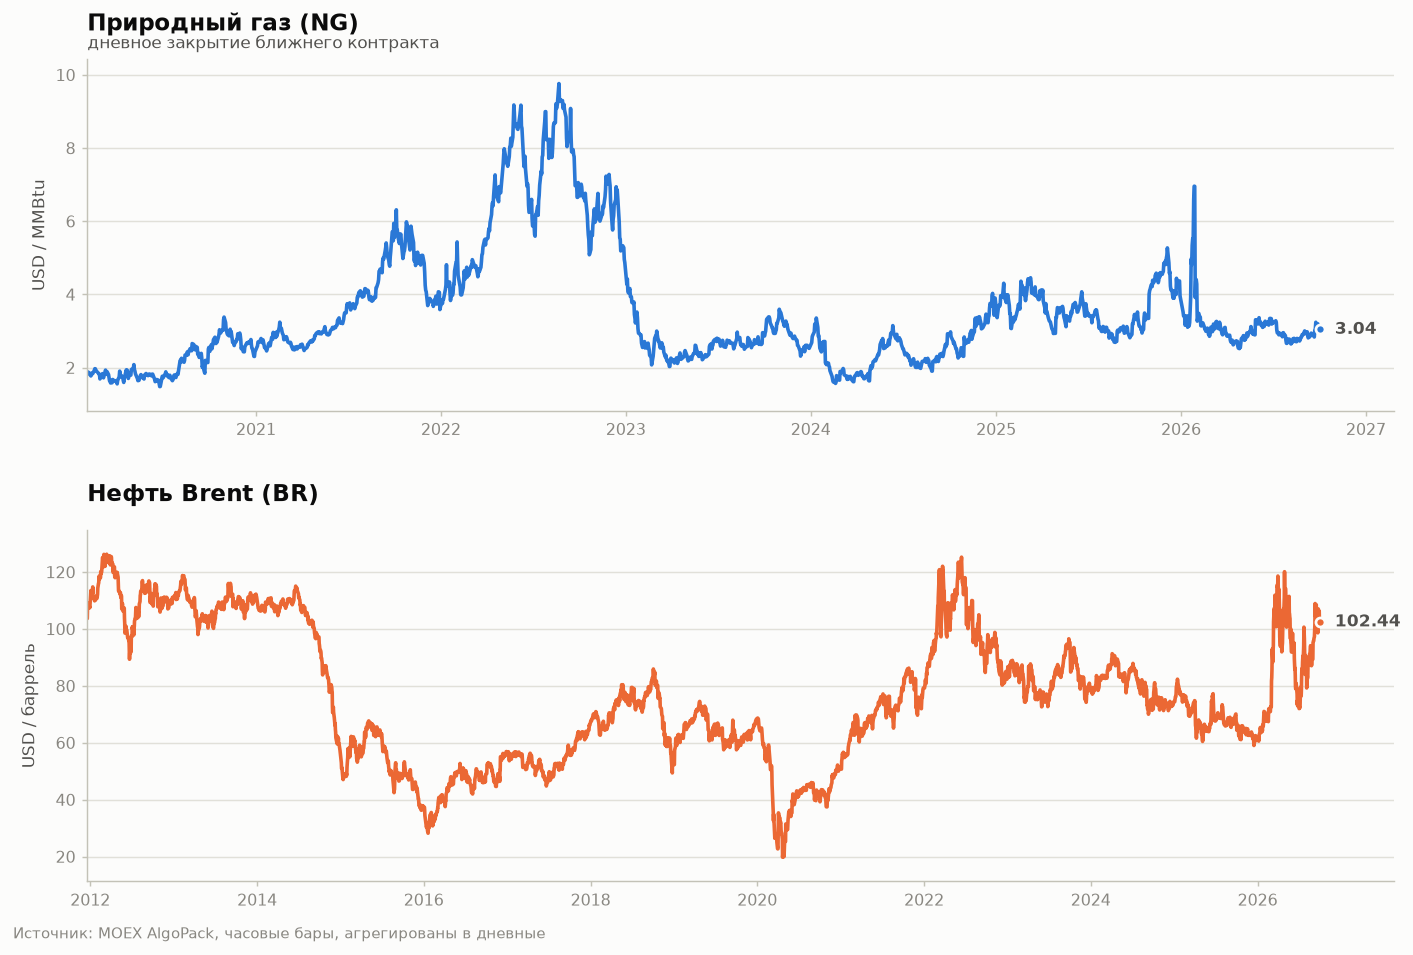

In [3]:
C.notebook_image("01_prices_ng_br.ipynb", 2)  # из ноутбука 01: дневные цены

## 4. Проверка 1: семь классических семейств стратегий

Первая проверка фреймворка на реальных данных (2026-10-07): дневные свечи, 12
ячеек «семейство × рынок», 125 конфигураций. Параметры подбирались **только** на
обучающих 60% истории; затем зазор в 10 баров и **одна** оценка на проверочном отрезке.
Издержки — около 7 базисных пунктов за оборот.

| № | Семейство | Тезис |
|---|---|---|
| 1 | Time-Series Momentum | тренд продолжается |
| 2 | Dual Moving Average | пересечение двух средних |
| 3 | Channel Breakout | пробой N-дневного экстремума |
| 4 | Cross-sectional momentum | сильный рынок обгоняет слабый |
| 5 | Carry / term structure | премия за форму срочной кривой |
| 6 | MA + portfolio | средние на портфеле из двух рынков |
| 7 | Momentum + reversal | моментум минус долгосрочный разворот |

Слева на графике — Шарп лучшей по обучающей выборке конфигурации (кольцо) и он же вне выборки
(точка). Справа — дефлированный Шарп: вероятность того, что истинный Шарп положителен, с учётом
**всех** 125 проверенных конфигураций.

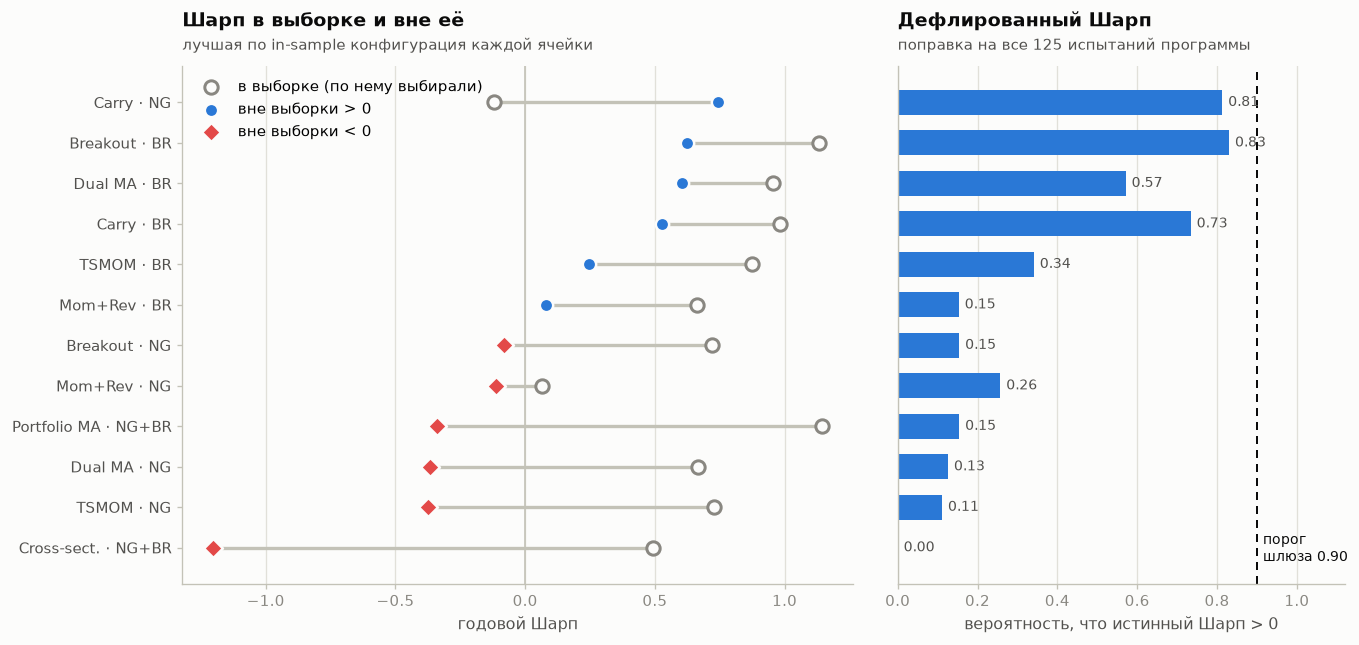

In [4]:
C.seven_families_chart()

**Что получилось.**

* **12 из 12 ячеек отклонены.** У каждой сработал заранее
  записанный критерий опровержения; чаще всего — дефлированный Шарп ниже порога 0.90.
* Вне выборки положительны 6 из 12. Вероятность получить столько
  же или больше при подбрасывании монеты — 0.61.
* Лучший дефлированный Шарп — 0.83 (Breakout · BR): с вероятностью
  около 17% и этот лучший результат объясняется самим перебором.
* **На BR трендовые эффекты есть:** все 5 односоставных семейств на BR вне
  выборки в плюсе (Шарп 0.08 … 0.62), а Hansen SPA по всем
  конфигурациям BR отвергает гипотезу «ни одна не лучше нуля» (p = 0.014; на NG
  p = 0.62). Но ни одна отдельная стратегия не проходит все шлюзы.

Отрицательный результат — это результат: он навсегда убирает кандидатов из поиска и делает
статистику следующих гипотез честной. Подробно — `docs/RESULTS_SEVEN_FAMILIES.md`, сделки на
графиках — ноутбук `02_trades_seven_families.ipynb`.

## 5. Проверка 2: пересечение скользящих средних на 5-минутных свечах

### 5.1. Задача

* **Вход:** цена пересекает быструю среднюю. Long — если медленная средняя направлена вверх
  или нейтральна, short — если вниз или нейтральна.
* **Направление медленной средней** — по её наклону за k баров: метод A — в процентах,
  метод B — в единицах ATR; нейтральная зона ±ε.
* **Выход A** — обратное пересечение быстрой средней. **Выход B** — медленная средняя
  развернулась в противоположную сторону.
* **Условия:** 1 контракт, исполнение по цене открытия следующей свечи, без издержек и стопов
  (так в задании), без мгновенного разворота.
* **Сетка:** быстрая 2–99, медленная 5–250, 6 типов средних (SMA, EMA, WMA, SSMA, VWMA, TMA) ×
  6 = 36 сочетаний, 2 метода наклона, 2 выхода. Всего конфигураций на инструмент:
  **3 471 552**.

**Порядок работы.** Этап 1 — полная сетка с заранее заданным наклоном (k = 5, нейтральны 25%
баров). Этап 2 — подбор параметров наклона на прореженной решётке, только по обучающей выборке.
Этап 3 — полная сетка заново с подобранным наклоном. Итого 13 886 208 полных бэктестов и
≈174 млрд сделок.

**Как обеспечена точность.** VectorBT напрямую не тянет 3.5 млн конфигураций × 600 тыс. свечей
(~2 ТБ сигналов). Поэтому написано событийное numba-ядро, которое сверено с
`vectorbt.Portfolio.from_signals` на реальных данных: **совпали 80 из 80
конфигураций, сделок в сверке — 1 106 822, максимальное расхождение в PnL —
2e-13.**
Шесть средних проверены против прямых формул, раскладка сетки — пересчётом случайных строк
с нуля.

### 5.2. Есть ли закономерность?

Без издержек прибыльна подавляющая часть сетки — в выборке и вне её:

In [5]:
C.stage_table()

прибыльны IS прибыльны OOS OOS без 2026  \
этап                    рынок                                           
1: исходный наклон      NG             85%           92%          91%   
                        BR             80%           73%          17%   
3: наклон оптимизирован NG             89%           84%          86%   
                        BR             83%           72%          23%   

                              OOS при 1 тике   PBO  SPA p  
этап                    рынок                              
1: исходный наклон      NG               54%  0.52  0.043  
                        BR               40%  0.30  0.011  
3: наклон оптимизирован NG               44%  0.47  0.061  
                        BR               43%  0.16  0.007

Чтобы понять, откуда прибыль, одни и те же конфигурации прогнаны на рядах, где разрушена
часть структуры:

In [6]:
C.nulls_table()

доля прибыльных  \
инструмент ряд                                           
NG         тот же ряд (контроль)                   86%   
           все свечи перемешаны                    36%   
           дни перемешаны целиком                  85%   
           свечи перемешаны внутри дня             65%   
BR         тот же ряд (контроль)                   81%   
           все свечи перемешаны                    18%   
           дни перемешаны целиком                  68%   
           свечи перемешаны внутри дня             38%   

                                        медиана средней сделки, тиков  
инструмент ряд                                                         
NG         тот же ряд (контроль)                                 3.89  
           все свечи перемешаны                                 -0.46  
           дни перемешаны целиком                                2.23  
           свечи перемешаны внутри дня                           0.97  
BR         тот же ряд (контроль)                                 0.49  
           все свечи перемешаны                                 -0.60  
           дни перемешаны целиком                                0.41  
           свечи перемешаны внутри дня                          -0.08

* **Все свечи перемешаны — прибыль исчезает.** Конвейер не создаёт прибыль из шума.
* **Перемешаны целые дни — прибыль остаётся.** Значит, это не многодневные тренды.
* **Перемешаны свечи внутри дня — у BR прибыль исчезает.** Источник — **инерция цены после
  пересечения внутри торгового дня**.

### 5.3. Миллионы конфигураций — это одно наблюдение

Все 3.47 млн конфигураций торгуют одну и ту же историю цены: удачная история делает прибыльными
почти все сразу. Поэтому «доля прибыльных конфигураций» сама по себе ничего не доказывает.
Корректная проверка — на уровне траектории: тот же показатель на реальном ряду против рядов, где
у каждой свечи случайно сменён знак (размер движений, кластеры волатильности и внутридневной
профиль сохранены, направленная предсказуемость уничтожена).

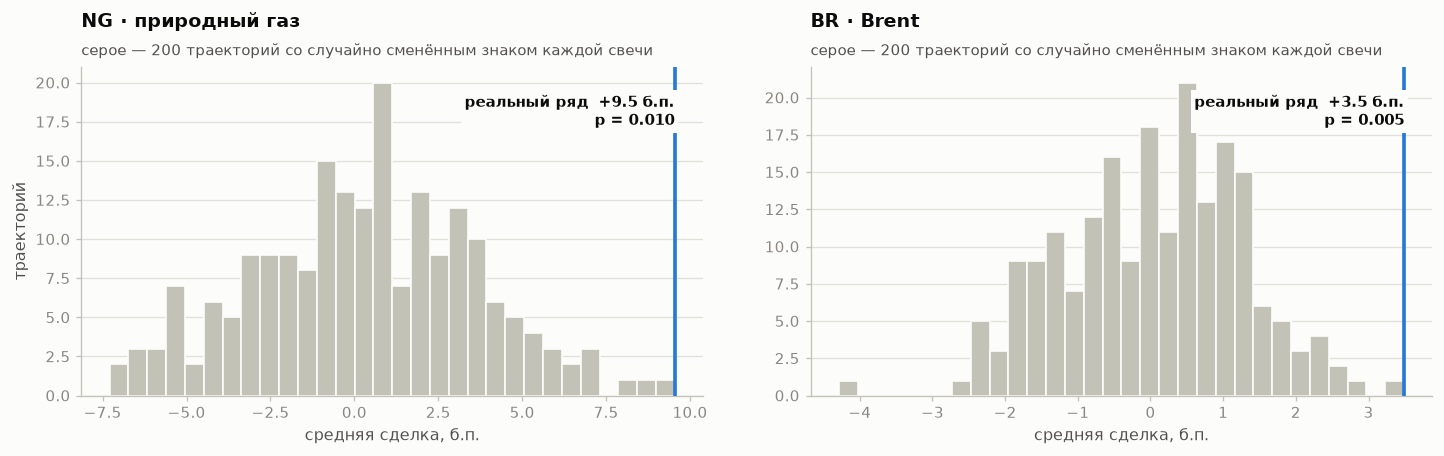

In [7]:
C.signflip_chart()

Реальный ряд лучше почти всех 200 случайных: средняя сделка
+9.5 б.п. против +0.3 ± 3.3 на NG
(p = 0.010) и +3.5 против +0.0 ± 1.2
на BR (p = 0.005). **Закономерность при нулевых издержках реальна.**

### 5.4. Издержки решают всё

Средняя сделка — от долей тика до нескольких тиков. Задание исключало издержки, поэтому они
добавлены как проверка чувствительности:

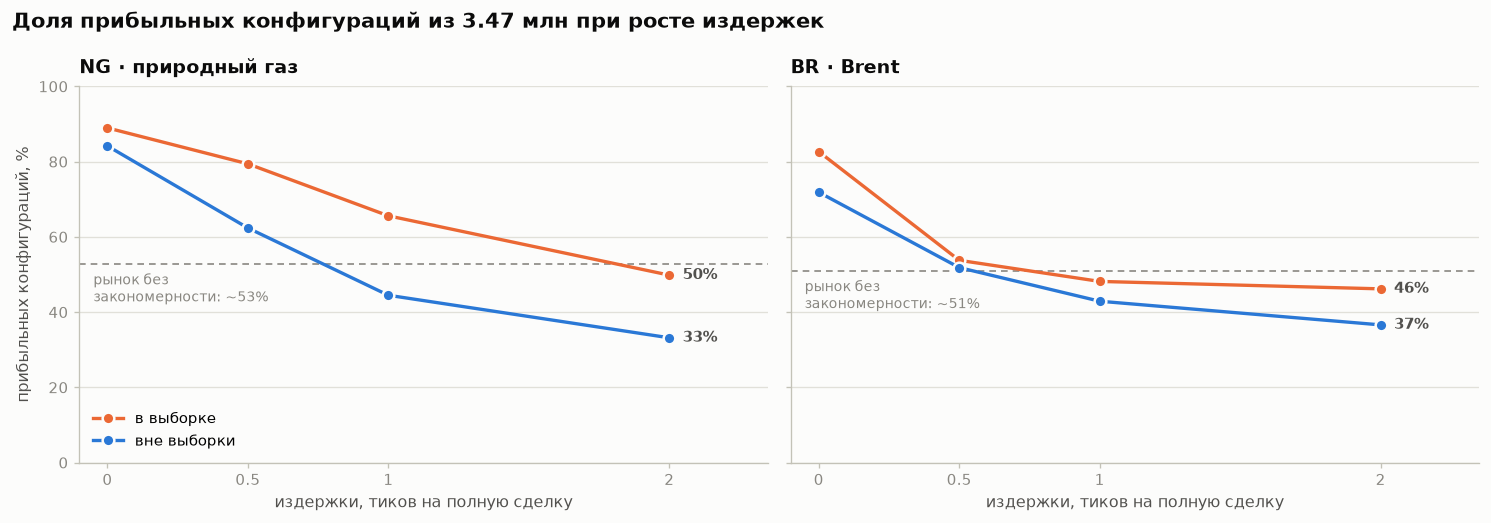

In [8]:
C.cost_ladder_chart("stage3")

Уже при 1 тике на сделку вне выборки прибыльны 44% конфигураций NG и
43% BR, при 2 тиках — 33% и 37%. После
реалистичных издержек **большинство конфигураций убыточно**, и доля прибыльных опускается ниже
той, что даёт рынок без всякой закономерности даже без издержек (~51%–53%).

### 5.5. Устойчивость во времени: NG держится, BR — нет

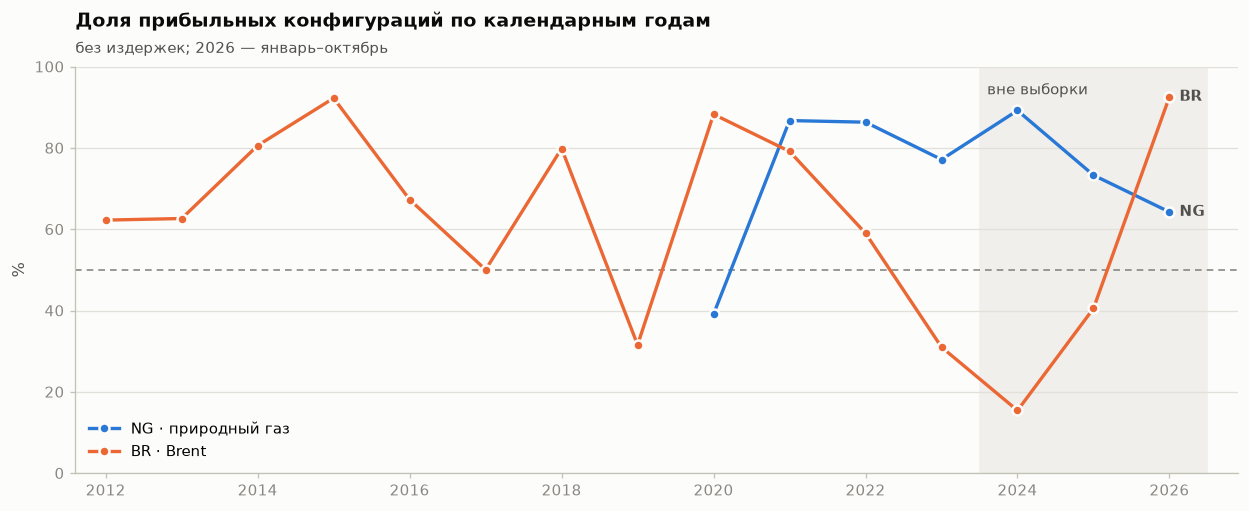

In [9]:
C.years_chart("stage3")

* **NG:** медианная конфигурация в плюсе в каждом году, кроме
  2020. Вне выборки без
  2026 года прибыльны 86% конфигураций, за весь период — 84%:
  результат не держится на одном годе.
* **BR:** в 2023 году прибыльны 31% конфигураций, в 2024 —
  15%, в 2025 — 41%, в 2026 —
  93%. «Прибыль вне выборки» у BR создана трендом 2026 года; без него
  прибыльны лишь 17%–23% конфигураций (этапы 1 и 3). Это
  зависимость от режима рынка, а не закономерность.

### 5.6. Подбор параметров не помогает

* **Точечный отбор лучших по обучающей выборке не работает.** PBO (вероятность, что отобранная
  конфигурация окажется хуже медианной вне выборки) у NG — 0.52 и 0.47
  на этапах 1 и 3, то есть около монетки; у BR — 0.30 и 0.16.
* **Walk-forward с переоптимизацией по всей сетке** (окно обучения 24 месяца, проверка 3 месяца)
  против «средней конфигурации»: ни один критерий отбора не превосходит её с t ≥ 2, а
  «лучший» критерий меняется от прогона к прогону. В таблице — t-статистика превышения:

In [10]:
C.wf_table()

отбор по PnL  по Шарпу  по плато
этап рынок                                  
1    NG            -1.23      0.36      0.35
     BR             0.67      0.09      1.73
3    NG            -1.72      0.25     -0.72
     BR            -0.91      1.88      0.26

* **Оптимизация наклона (этап 3) — классическое переобучение на NG:** доля прибыльных
  в выборке выросла, а вне выборки упала с 92% до 84%.
* **Рейтинг 36 сочетаний типов средних вне выборки не воспроизводится:** выбор типа средней —
  это шум.

Каждая точка ниже — одна из 3.47 млн конфигураций: её результат в выборке против результата вне
выборки.

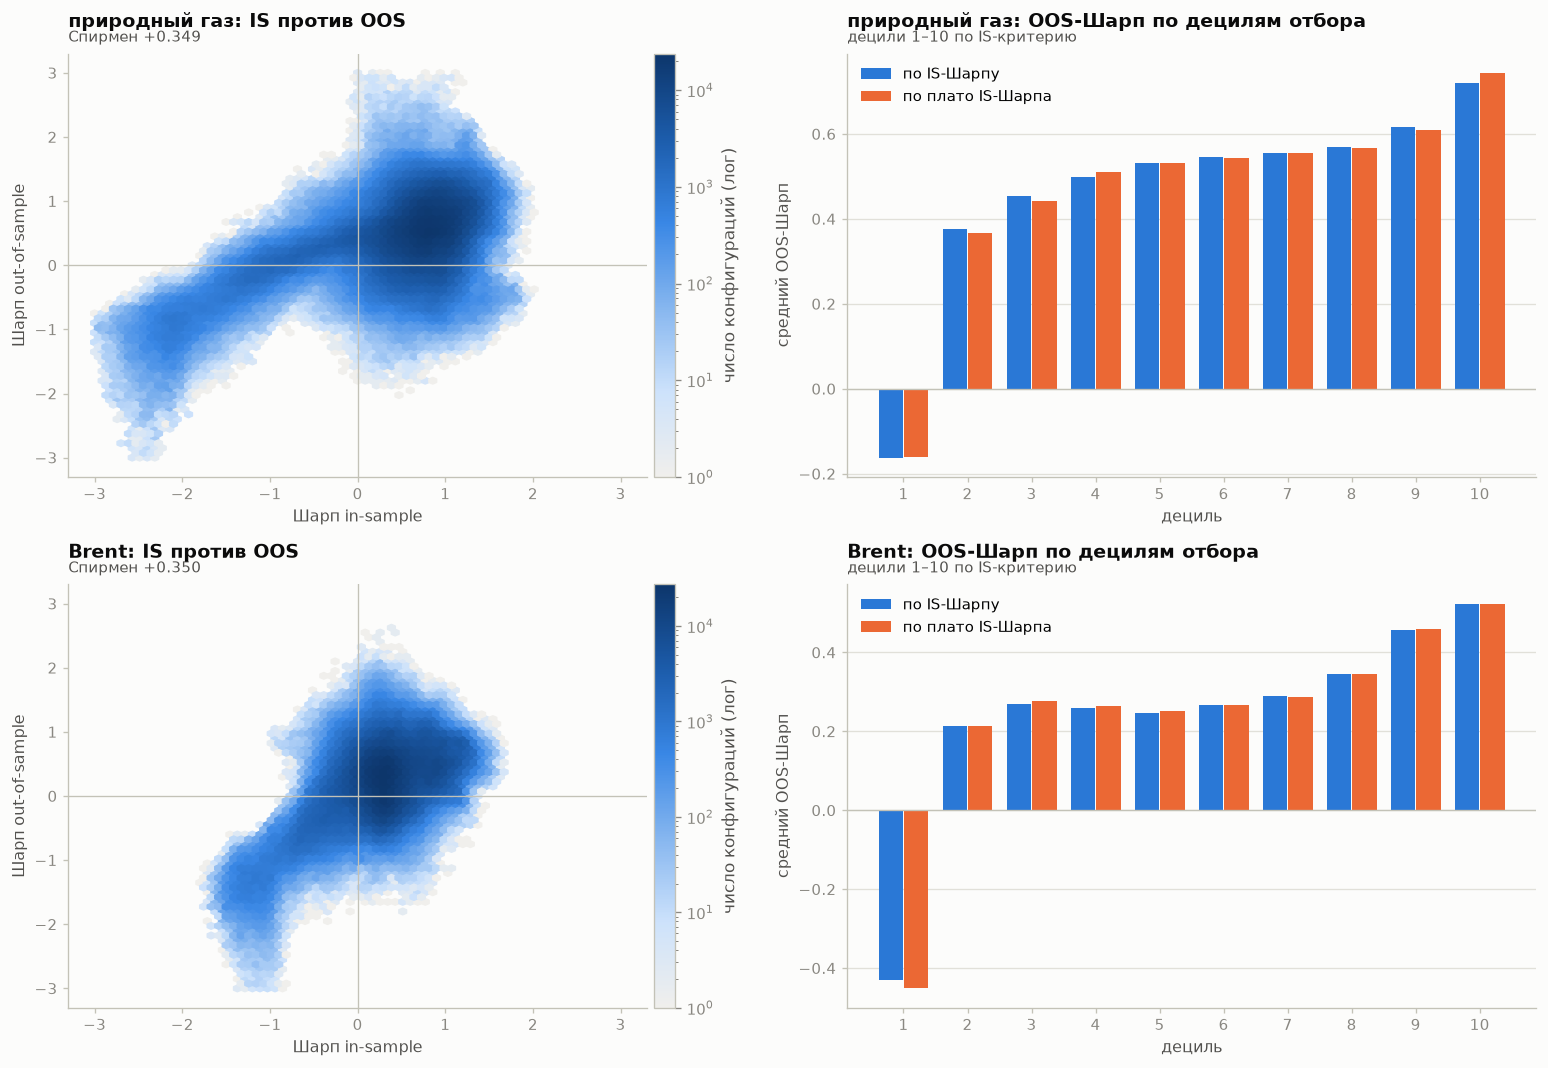

In [11]:
C.figure("09_is_vs_oos.png")

### 5.7. Что действительно имеет значение

Переносится вне выборки на обоих рынках:

* **Модель выхода.** Выход по развороту медленной средней (B) лучше выхода по обратному
  пересечению (A). У BR выход A даёт около 0.2 тика на сделку — практически ноль.
* **Период определения наклона k.** На BR результат растёт с k до 34–55 баров (3–4.5 часа),
  дальше падает. Оптимум внутренний: он найден продлением сетки за прежнюю границу.
* **Метод нейтральной зоны.** По результату A и B неразличимы, но метод B (через ATR) в 2–6 раз
  стабильнее держит долю нейтральных баров между выборками.

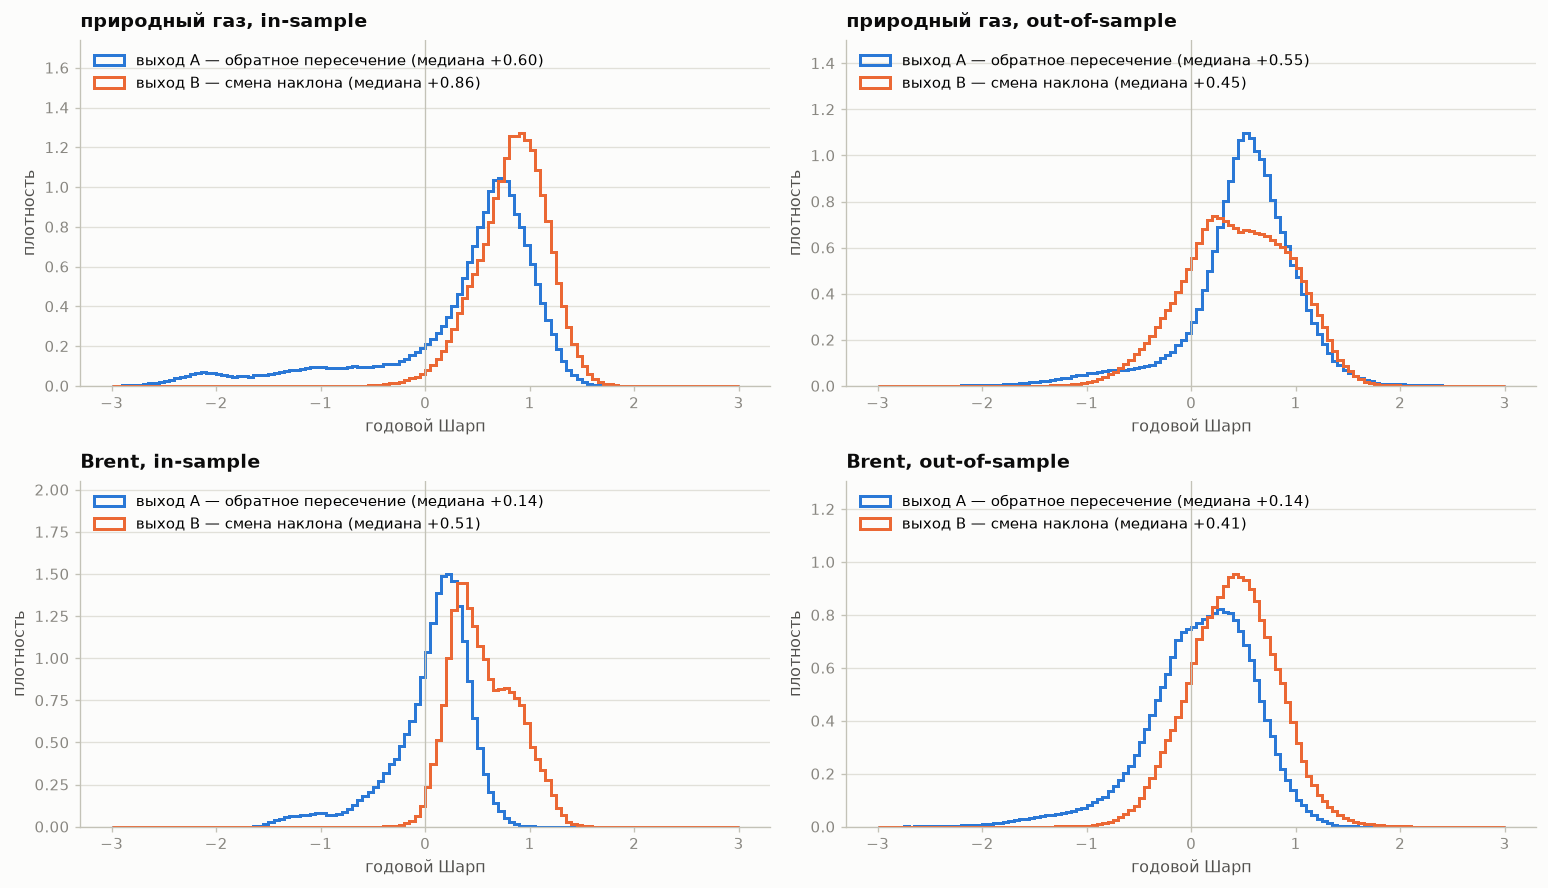

In [12]:
C.figure("03_exits.png")

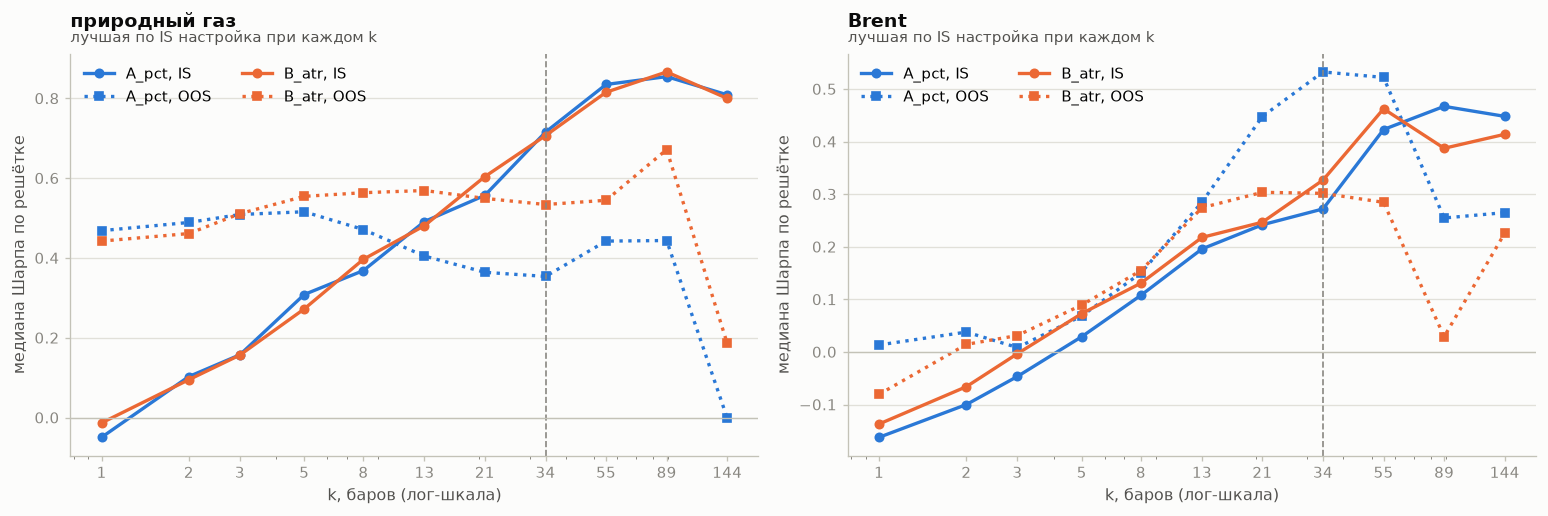

In [13]:
C.figure("04b_slope_period_k.png")

### 5.8. Лучший кандидат — и почему он ещё не стратегия

Ближе всего к торговому результату группа **«верхний 1% конфигураций по результату в выборке
за вычетом 2 тиков на сделку»**: редко торгующие конфигурации с выходом B. Проверка на данных
2024–2025 годов, то есть без трендового 2026-го:

In [14]:
C.topcheck_table()

прибыльны в 2024–2025  USD в месяц на контракт  \
этап рынок издержки, тиков                                                  
1    NG    1                                 99%                     11.1   
           2                                 97%                      9.1   
     BR    1                                 14%                     -4.9   
           2                                  6%                     -6.7   
3    NG    1                                 86%                      6.9   
           2                                 82%                      6.0   
     BR    1                                 44%                     -0.2   
           2                                 32%                     -1.4   

                            t-статистика  
этап рынок издержки, тиков                
1    NG    1                        2.09  
           2                        1.71  
     BR    1                       -0.76  
           2                       -1.03  
3    NG    1                        0.95  
           2                        0.82  
     BR    1                       -0.02  
           2                       -0.18

* **NG, этап 1:** при 2 тиках прибыльны 97% конфигураций группы;
  +11 USD в месяц на контракт при 1 тике (t = 2.1) и
  +9 USD при 2 тиках (t = 1.7).
* **NG, этап 3:** после оптимизации наклона та же проверка даёт t ≈ 0.9.
* **BR:** за 2024–2025 при 2 тиках прибыльны лишь 6% конфигураций группы.

t ≈ 1.7–2.1 — пограничный результат. Это одна группа из двенадцати проверенных, одна история
цены, издержки смоделированы, а не взяты из реального спреда. После поправки на число
проверенных групп этого недостаточно.

### 5.9. Вердикт по скользящим средним

**Статистическая закономерность есть, торгового преимущества не доказано.** Внутридневная
инерция после пересечения реальна (тест траекторий p ≈ 0.01) и на NG устойчива во времени. Но
средняя сделка сопоставима с минимальной ценой сделки, подбор параметров не улучшает результат
вне выборки, а единственная группа, пережившая издержки, проходит временной тест на грани
значимости. Подробно — `docs/RESULTS_MA_CROSSOVER_5M.md` и ноутбук `03_ma_crossover_5m.ipynb`.

## 6. Итог

| Что | Результат |
|---|---|
| Аудит исходного проекта | Найдена ошибка, обесценившая все прежние результаты: проверочный период участвовал в отборе. Плюс отсутствие поправок на перебор, исполнение по цене сигнальной свечи и небезопасный запуск агента. |
| Новая система | Exchange Research OS: конвейер «на опровержение», честность обеспечена устройством кода, 527 тестов, ИИ-цикл не включён до появления песочницы. |
| Семь семейств, дневки, NG и BR | 12 из 12 отклонены. Тренд на BR заметен (SPA p = 0.014), но ни одна стратегия не проходит шлюзы. |
| Скользящие средние, 5 минут, NG и BR | 13 886 208 бэктестов. Закономерность при нулевых издержках реальна (p ≈ 0.01), но после издержек большинство конфигураций убыточно; на BR результат зависит от режима рынка; лучший кандидат на NG пограничен (t ≈ 2.1). |

**Чего удалось достичь.** Фреймворк сделал то, ради чего строился: не дал принять за
преимущество ни случайность (семь семейств), ни переобучение (оптимизация наклона на NG), ни
зависимость от одного режима рынка (BR в 2026 году). В процессе он нашёл и **собственную**
ошибку: тест Hansen SPA на чистом шуме отвергал нулевую гипотезу в 35–100% случаев вместо 5%.
Ошибка исправлена (bootstrap-t), закреплена тестом калибровки, отчёт по семи семействам
пересчитан; выводы не изменились.

## 7. Что дальше

1. **NG: одна гипотеза вместо сетки.** Выход B, k ≈ 34–89, медленная средняя длиннее быстрой,
   отбор по результату за вычетом издержек. Зафиксировать заранее, проверить на **реальном
   спреде** (котировки bid/ask, а не цены открытия) и на новом участке данных.
2. **BR: сначала понять режимы.** Почему 2023–2025 годы провальны для всего семейства — и только
   потом что-то оптимизировать.
3. **Не расширять сетку.** Новые типы средних и периоды лишь увеличивают число испытаний, не
   добавляя информации.
4. **Песочница — потом ИИ-цикл.** Именно в таком порядке.

## 8. Где что лежит

| Материал | Путь |
|---|---|
| Описание фреймворка | [`exchange/README.md`](../README.md) |
| Аудит исходного проекта | [`docs/ARCHITECTURE_AUDIT.md`](../docs/ARCHITECTURE_AUDIT.md) |
| Методология статистики | [`docs/METHODOLOGY.md`](../docs/METHODOLOGY.md) |
| Требования к ИИ-исследователю | [`docs/AI_RESEARCHER.md`](../docs/AI_RESEARCHER.md) |
| Отчёт: семь семейств | [`docs/RESULTS_SEVEN_FAMILIES.md`](../docs/RESULTS_SEVEN_FAMILIES.md) |
| Отчёт: скользящие средние | [`docs/RESULTS_MA_CROSSOVER_5M.md`](../docs/RESULTS_MA_CROSSOVER_5M.md) |
| Ноутбук: цены, волатильность, MACD | [`01_prices_ng_br.ipynb`](01_prices_ng_br.ipynb) |
| Ноутбук: сделки семи семейств | [`02_trades_seven_families.ipynb`](02_trades_seven_families.ipynb) |
| Ноутбук: скользящие средние, все графики | [`03_ma_crossover_5m.ipynb`](03_ma_crossover_5m.ipynb) |
| Журнал сделок: каждая сделка каждой оптимизированной системы и её результат (Excel и CSV), проверка полноты — `AUDIT.md` | [`research/trade_logs/`](../research/trade_logs/README.md) |
| Таблицы и полная сетка (2 рынка × 2 этапа × 3 471 552) | [`research/ma_crossover_5m/results/`](../research/ma_crossover_5m/results/) |
| Код исследования и команды воспроизведения | [`research/ma_crossover_5m/README.md`](../research/ma_crossover_5m/README.md) |

Этот ноутбук пересобирается командой `python research/presentation/build.py` из каталога
`exchange/` и исполняется за секунды: исходные данные ему не нужны, только файлы результатов.